# Proyecto: Sweet Lift Taxi

La compañía Sweet Lift Taxi ha recopilado datos históricos sobre pedidos de taxis en los aeropuertos. Para atraer a más conductores durante las horas pico, necesitamos predecir la cantidad de pedidos de taxis para la próxima hora. Construye un modelo para dicha predicción.

La métrica RECM en el conjunto de prueba no debe ser superior a 48.

## Objetivo general

Construir un modelo que prediga la cantidad de pedidos de taxi de la próxima hora, con una RECM de prueba menor o igual a 48. La muestra de prueba es el último 10 % de la serie.

## Instrucciones del proyecto

1. Descarga los datos y remuestréalos de tal forma que cada punto de datos de los datos originales caiga dentro de intervalos de una hora.
2. Analiza los datos.
3. Entrena diferentes modelos con diferentes hiperparámetros. La muestra de prueba debe ser el 10 % del conjunto de datos inicial.
4. Prueba los datos usando la muestra de prueba y proporciona una conclusión.

## Descripción de los datos

Los datos se almacenan en el archivo `taxi.csv`. El número de pedidos está en la columna `num_orders` y la columna `datetime` marca el momento de cada registro.

## 1. Preparación

**Objetivo:** cargar los datos, revisar que estén completos y ordenados en el tiempo, y remuestrearlos a intervalos de una hora para tener una serie con un paso temporal constante.

In [ ]:
# importaciones que usaremos en todo el proyecto
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose  # descomposición de la serie
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error

# al crear muchas columnas de desfase pandas lanza un aviso de rendimiento, lo silenciamos
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

In [3]:
# cargamos los datos usando la fecha como índice
# en el try va la ruta local, en el except la ruta de la plataforma
try:
    datos = pd.read_csv('taxi.csv', index_col=[0], parse_dates=[0])
except FileNotFoundError:
    datos = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])

datos.head()

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [4]:
# revisamos el estado de los datos antes de remuestrear
print(datos.info())
print()
print('Valores ausentes:', datos['num_orders'].isna().sum())
print('Fechas duplicadas:', datos.index.duplicated().sum())
print('¿El índice está ordenado en el tiempo?', datos.index.is_monotonic_increasing)
print('Primer registro:', datos.index.min())
print('Último registro:', datos.index.max())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB
None

Valores ausentes: 0
Fechas duplicadas: 0
¿El índice está ordenado en el tiempo? True
Primer registro: 2018-03-01 00:00:00
Último registro: 2018-08-31 23:50:00


In [5]:
# remuestreamos a intervalos de una hora
# ordenamos por si acaso y sumamos los pedidos que caen dentro de cada hora
datos = datos.sort_index().resample('1H').sum()

print('Filas después del remuestreo:', datos.shape[0])
print('¿El índice sigue ordenado?', datos.index.is_monotonic_increasing)
print()
print(datos['num_orders'].describe())
datos.head()

Filas después del remuestreo: 4416
¿El índice sigue ordenado? True

count    4416.000000
mean       84.422781
std        45.023853
min         0.000000
25%        54.000000
50%        78.000000
75%       107.000000
max       462.000000
Name: num_orders, dtype: float64


/var/folders/tp/tccs84bn713ckxl_07sqv3_40000gn/T/ipykernel_27590/2216764123.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  datos = datos.sort_index().resample('1H').sum()


,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


**Conclusión:** los datos crudos traen 26.496 registros tomados cada 10 minutos, del 1 de marzo al 31 de agosto de 2018, sin valores ausentes, sin fechas duplicadas y con el índice ya ordenado. Al remuestrear a una hora con la suma obtengo 4.416 horas. Uso la suma y no la media porque me interesa el total de pedidos de cada hora, que es lo que el modelo tiene que predecir. La serie por hora tiene una media de 84.4 pedidos, con un máximo de 462.

## 2. Análisis

**Objetivo:** entender el comportamiento de la serie antes de modelar. Quiero ver si hay tendencia, qué estacionalidad tiene (por hora del día y por día de la semana) y si la serie es estacionaria, porque todo eso decide qué características le voy a dar al modelo.

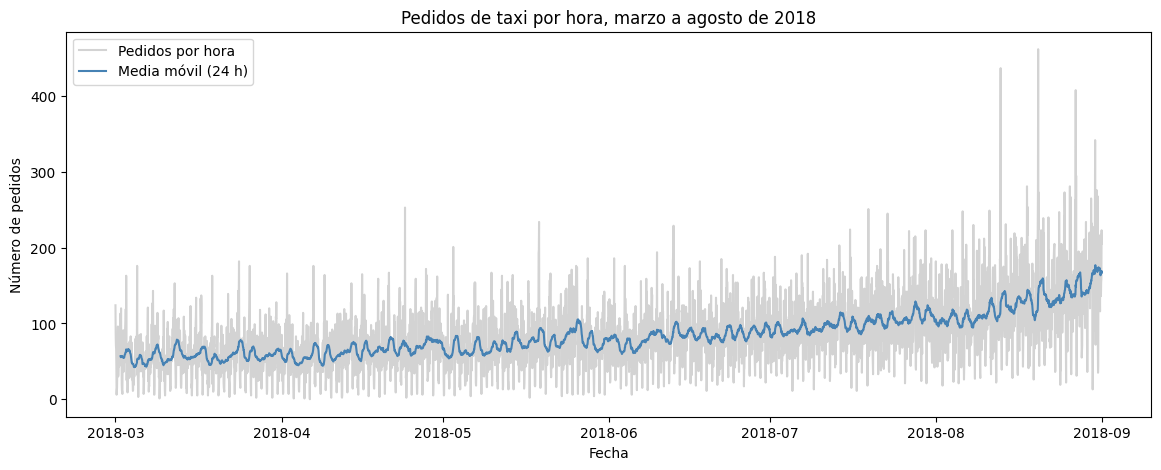

In [6]:
# graficamos la serie completa por hora junto con su media móvil de 24 horas
# la media móvil suaviza el ruido y deja ver la tendencia
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(datos.index, datos['num_orders'], color='lightgray', label='Pedidos por hora')
ax.plot(datos.index, datos['num_orders'].rolling(24).mean(), color='steelblue', label='Media móvil (24 h)')
ax.set_title('Pedidos de taxi por hora, marzo a agosto de 2018')
ax.set_xlabel('Fecha')
ax.set_ylabel('Número de pedidos')
ax.legend()
plt.show()

/var/folders/tp/tccs84bn713ckxl_07sqv3_40000gn/T/ipykernel_27590/4142461100.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  media_mensual = datos['num_orders'].resample('1M').mean()


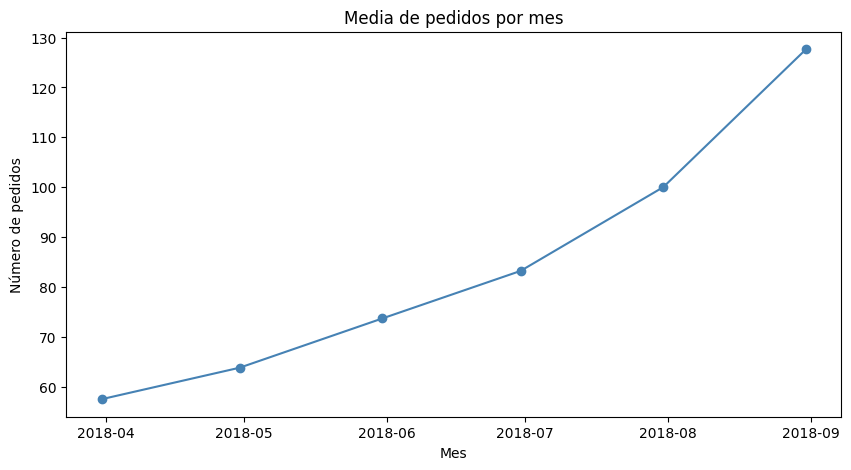

datetime
2018-03-31     57.5
2018-04-30     63.8
2018-05-31     73.7
2018-06-30     83.2
2018-07-31    100.0
2018-08-31    127.7
Freq: ME, Name: num_orders, dtype: float64


In [7]:
# vemos la tendencia mes a mes con la media mensual
media_mensual = datos['num_orders'].resample('1M').mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(media_mensual.index, media_mensual.values, marker='o', color='steelblue')
ax.set_title('Media de pedidos por mes')
ax.set_xlabel('Mes')
ax.set_ylabel('Número de pedidos')
plt.show()

print(media_mensual.round(1))

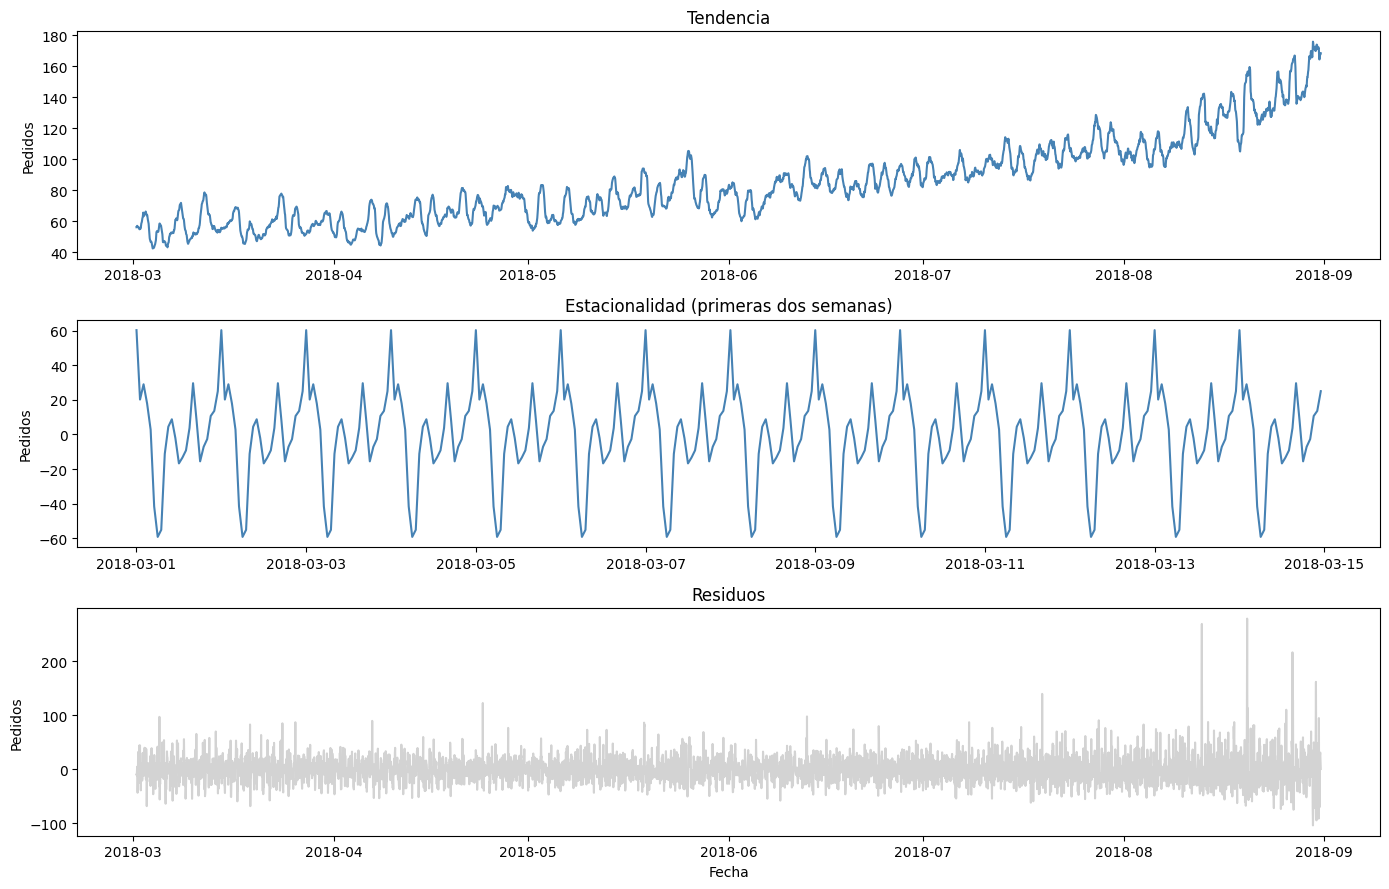

In [8]:
# descomponemos la serie en tendencia, estacionalidad y residuos
# usamos period=24 porque el ciclo que esperamos es diario (24 horas)
descomposicion = seasonal_decompose(datos['num_orders'], period=24)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 9))

ax1.plot(descomposicion.trend.index, descomposicion.trend, color='steelblue')
ax1.set_title('Tendencia')
ax1.set_ylabel('Pedidos')

# graficamos solo las primeras dos semanas para ver bien el ciclo diario
dos_semanas = descomposicion.seasonal.iloc[:24 * 14]
ax2.plot(dos_semanas.index, dos_semanas, color='steelblue')
ax2.set_title('Estacionalidad (primeras dos semanas)')
ax2.set_ylabel('Pedidos')

ax3.plot(descomposicion.resid.index, descomposicion.resid, color='lightgray')
ax3.set_title('Residuos')
ax3.set_xlabel('Fecha')
ax3.set_ylabel('Pedidos')

plt.tight_layout()
plt.show()

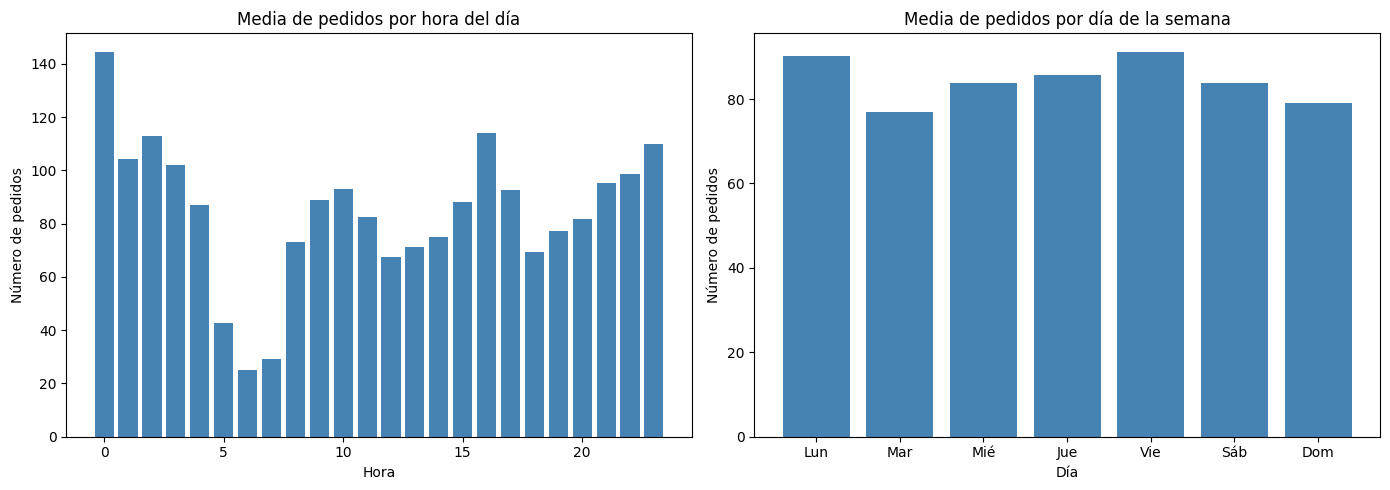

In [9]:
# calculamos la media de pedidos por hora del día y por día de la semana
# así vemos la estacionalidad de forma más directa que en la descomposición
media_por_hora = datos.groupby(datos.index.hour)['num_orders'].mean()
media_por_dia = datos.groupby(datos.index.dayofweek)['num_orders'].mean()
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.bar(media_por_hora.index, media_por_hora.values, color='steelblue')
ax1.set_title('Media de pedidos por hora del día')
ax1.set_xlabel('Hora')
ax1.set_ylabel('Número de pedidos')

ax2.bar(dias, media_por_dia.values, color='steelblue')
ax2.set_title('Media de pedidos por día de la semana')
ax2.set_xlabel('Día')
ax2.set_ylabel('Número de pedidos')

plt.tight_layout()
plt.show()

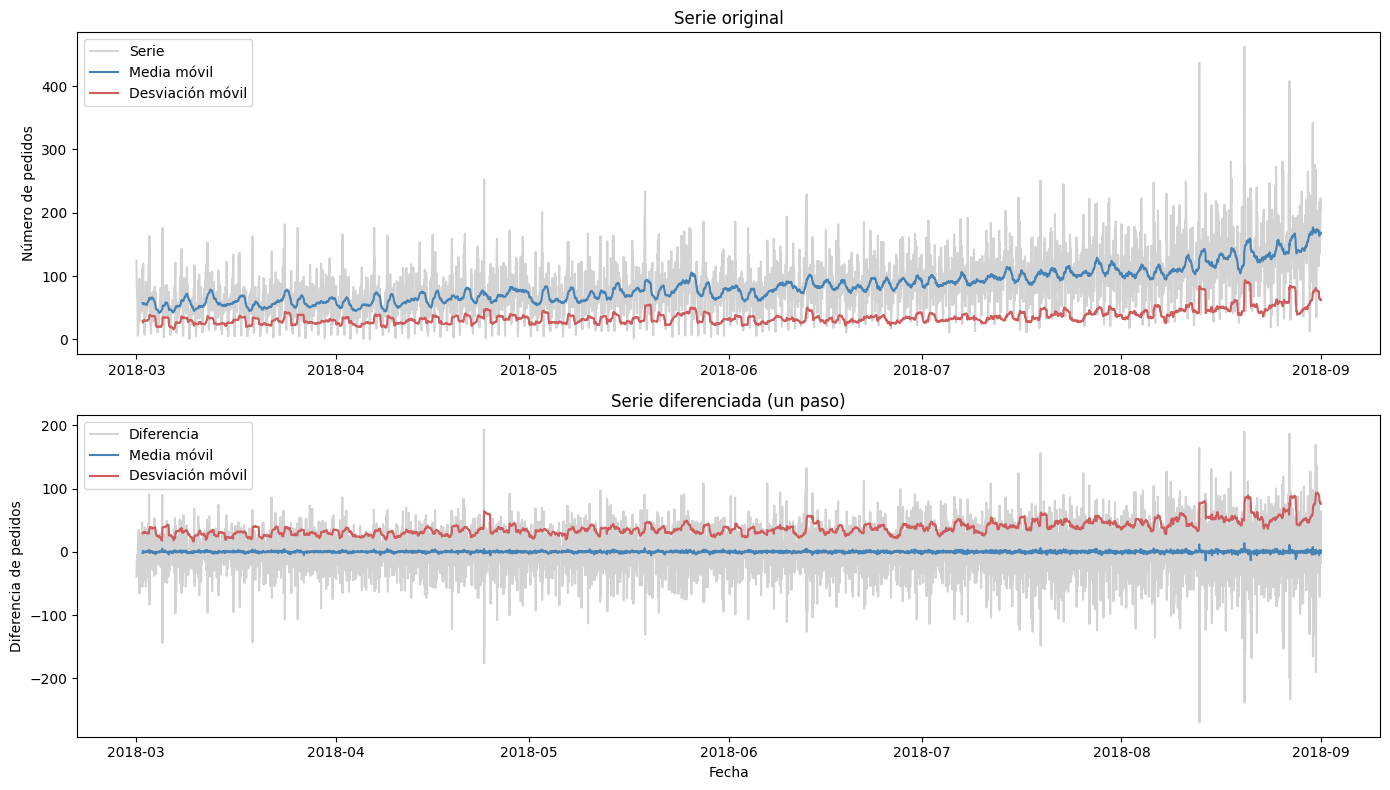

Media de la serie original: 84.42
Media de la serie diferenciada: 0.018


In [10]:
# revisamos la estacionariedad comparando la serie original con su diferencia de un paso
# si la media y la desviación móviles se mantienen planas, la serie es más estacionaria
diferencia = datos['num_orders'].diff()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

ax1.plot(datos.index, datos['num_orders'], color='lightgray', label='Serie')
ax1.plot(datos.index, datos['num_orders'].rolling(24).mean(), color='steelblue', label='Media móvil')
ax1.plot(datos.index, datos['num_orders'].rolling(24).std(), color='indianred', label='Desviación móvil')
ax1.set_title('Serie original')
ax1.set_ylabel('Número de pedidos')
ax1.legend()

ax2.plot(diferencia.index, diferencia, color='lightgray', label='Diferencia')
ax2.plot(diferencia.index, diferencia.rolling(24).mean(), color='steelblue', label='Media móvil')
ax2.plot(diferencia.index, diferencia.rolling(24).std(), color='indianred', label='Desviación móvil')
ax2.set_title('Serie diferenciada (un paso)')
ax2.set_xlabel('Fecha')
ax2.set_ylabel('Diferencia de pedidos')
ax2.legend()

plt.tight_layout()
plt.show()

print('Media de la serie original:', round(datos['num_orders'].mean(), 2))
print('Media de la serie diferenciada:', round(diferencia.mean(), 3))

**Conclusión:** la serie tiene una tendencia creciente clara, la media mensual pasa de 57.5 pedidos en marzo a 127.7 en agosto. Encima de esa tendencia hay una estacionalidad diaria fuerte: el pico está a la medianoche con 144.4 pedidos de media y el valle a las 6 de la mañana con 25.2. El componente estacional diario oscila entre unos -59 y +60 pedidos. El efecto del día de la semana existe pero es mucho más débil. La serie original no es estacionaria porque su media sube con el tiempo, pero al aplicar una diferencia de un paso la media de la serie queda casi en cero (0.018) y se estabiliza. Esto nos dice dos cosas para modelar: se necesitan características de calendario (hora y día de la semana) y características de desfase que le pasen al modelo los valores recientes, porque la tendencia y el ciclo diario se capturan bien con el pasado cercano.

## 3. Formación

**Objetivo:** crear las características que necesita el modelo (calendario, desfases y media móvil), separar los datos en orden cronológico dejando el último 10 % para la prueba, y entrenar varios modelos con distintos hiperparámetros eligiendo el mejor con una muestra de validación. Comparo todo contra tres líneas base para saber si los modelos aportan algo.

In [11]:
# función para calcular la RECM, que es la métrica del proyecto
def calcular_recm(y_real, y_pred):
    return mean_squared_error(y_real, y_pred) ** 0.5


# función que crea las características de la serie
# max_lag: cuántos valores anteriores incluimos como columnas de desfase
# rolling_mean_size: tamaño de la ventana de la media móvil
def crear_caracteristicas(datos, max_lag, rolling_mean_size):
    datos = datos.copy()

    # características de calendario
    datos['dayofweek'] = datos.index.dayofweek
    datos['hour'] = datos.index.hour

    # características de desfase, los valores de horas anteriores
    for retraso in range(1, max_lag + 1):
        datos['lag_' + str(retraso)] = datos['num_orders'].shift(retraso)

    # media móvil calculada sobre la serie desplazada un paso
    # usamos shift() para no incluir la hora que queremos predecir
    datos['rolling_mean'] = datos['num_orders'].shift().rolling(rolling_mean_size).mean()

    return datos

In [12]:
# separamos los datos en orden cronológico, sin barajar
# primero apartamos el último 10 % como prueba
# luego apartamos un 10 % del resto como validación para elegir hiperparámetros
train_full, test = train_test_split(datos, shuffle=False, test_size=0.1)
train, valid = train_test_split(train_full, shuffle=False, test_size=0.1)

print('Entrenamiento:', len(train), 'horas, de', train.index.min(), 'a', train.index.max())
print('Validación:', len(valid), 'horas, de', valid.index.min(), 'a', valid.index.max())
print('Prueba:', len(test), 'horas, de', test.index.min(), 'a', test.index.max())
print()
print('Media de pedidos en entrenamiento:', round(train['num_orders'].mean(), 1))
print('Media de pedidos en validación:', round(valid['num_orders'].mean(), 1))
print('Media de pedidos en prueba:', round(test['num_orders'].mean(), 1))

Entrenamiento: 3576 horas, de 2018-03-01 00:00:00 a 2018-07-27 23:00:00
Validación: 398 horas, de 2018-07-28 00:00:00 a 2018-08-13 13:00:00
Prueba: 442 horas, de 2018-08-13 14:00:00 a 2018-08-31 23:00:00

Media de pedidos en entrenamiento: 74.7
Media de pedidos en validación: 110.3
Media de pedidos en prueba: 139.6


In [13]:
# calculamos tres líneas base sobre la validación para tener una referencia
# 1) una constante, la mediana del entrenamiento
# 2) el valor de la hora anterior
# 3) el valor de la misma hora de la semana anterior (168 horas antes)
base_mediana = calcular_recm(valid['num_orders'], np.full(len(valid), train['num_orders'].median()))
base_anterior = calcular_recm(valid['num_orders'], datos['num_orders'].shift(1).loc[valid.index])
base_semana = calcular_recm(valid['num_orders'], datos['num_orders'].shift(168).loc[valid.index])

print('Líneas base en validación (RECM):')
print('Mediana constante:', round(base_mediana, 2))
print('Valor de la hora anterior:', round(base_anterior, 2))
print('Valor de la semana anterior:', round(base_semana, 2))

Líneas base en validación (RECM):
Mediana constante: 60.17
Valor de la hora anterior: 47.27
Valor de la semana anterior: 34.25


In [14]:
# probamos distintos modelos e hiperparámetros, variando también cuántos desfases usamos
# guardamos cada resultado de validación en una lista para armar una tabla al final

# modelos a probar, cada uno con un par de combinaciones de hiperparámetros
modelos = {
    'Regresión lineal': [LinearRegression()],
    'Árbol de decisión': [
        DecisionTreeRegressor(max_depth=8, random_state=12345),
        DecisionTreeRegressor(max_depth=12, random_state=12345),
    ],
    'Bosque aleatorio': [
        RandomForestRegressor(n_estimators=100, max_depth=10, random_state=12345, n_jobs=-1),
        RandomForestRegressor(n_estimators=200, max_depth=15, random_state=12345, n_jobs=-1),
    ],
    'LightGBM': [
        LGBMRegressor(n_estimators=100, num_leaves=31, learning_rate=0.1, random_state=12345, verbose=-1),
        LGBMRegressor(n_estimators=200, num_leaves=63, learning_rate=0.05, random_state=12345, verbose=-1),
    ],
}

resultados = []

# probamos distintos tamaños de desfase y de ventana de media móvil
for max_lag in [24, 48, 168]:
    for rolling_mean_size in [24, 168]:
        # creamos las características y repetimos el mismo corte cronológico
        caracteristicas = crear_caracteristicas(datos, max_lag, rolling_mean_size)
        c_train_full, c_test = train_test_split(caracteristicas, shuffle=False, test_size=0.1)
        c_train, c_valid = train_test_split(c_train_full, shuffle=False, test_size=0.1)

        # quitamos los NaN de los primeros desfases solo en el entrenamiento
        c_train = c_train.dropna()

        X_train = c_train.drop('num_orders', axis=1)
        y_train = c_train['num_orders']
        X_valid = c_valid.drop('num_orders', axis=1)
        y_valid = c_valid['num_orders']

        for nombre, lista_modelos in modelos.items():
            for modelo in lista_modelos:
                modelo.fit(X_train, y_train)
                recm_valid = calcular_recm(y_valid, modelo.predict(X_valid))
                resultados.append([nombre, max_lag, rolling_mean_size,
                                   modelo.get_params().get('max_depth'),
                                   modelo.get_params().get('num_leaves'),
                                   round(recm_valid, 2)])

tabla = pd.DataFrame(resultados,
                     columns=['modelo', 'max_lag', 'rolling_mean', 'max_depth', 'num_leaves', 'recm_valid'])
tabla = tabla.sort_values('recm_valid').reset_index(drop=True)
tabla.head(10)

,modelo,max_lag,rolling_mean,max_depth,num_leaves,recm_valid
0,Regresión lineal,168,168,NaN,NaN,28.43
1,Regresión lineal,168,24,NaN,NaN,28.43
2,LightGBM,168,24,-1.0,63.0,28.80
3,LightGBM,168,168,-1.0,31.0,29.40
4,LightGBM,168,168,-1.0,63.0,29.50
5,Bosque aleatorio,168,24,15.0,NaN,29.54
6,Bosque aleatorio,168,168,15.0,NaN,29.63
7,LightGBM,168,24,-1.0,31.0,29.63
8,Bosque aleatorio,168,168,10.0,NaN,29.75
9,Bosque aleatorio,168,24,10.0,NaN,29.81


**Conclusión:** la mejor línea base en validación es predecir con el valor de la misma hora de la semana anterior, con una RECM de 34.25, bastante por debajo de la mediana constante (60.17) y del valor de la hora anterior (47.27). Eso confirma que el patrón semanal y diario tiene mucha información. La regresión lineal con 168 desfases es la más precisa en validación, con una RECM de 28.43, seguida muy de cerca por LightGBM (28.80) y el bosque aleatorio (29.54). El único modelo que no mejora la línea base semanal es el árbol de decisión simple, que se queda en unos 37. El número de desfases importa más que el modelo: con solo 24 desfases ningún modelo baja de 30, y al pasar a 168 la regresión lineal y los modelos de conjunto sí lo logran. Me quedo con la regresión lineal y 168 desfases porque da la mejor RECM, es la más simple y la más rápida de entrenar, y sirve además como prueba de cordura de los modelos de árbol.

## 4. Prueba

**Objetivo:** reentrenar el mejor modelo elegido en validación (regresión lineal con 168 desfases) usando entrenamiento más validación, y medirlo una sola vez en el conjunto de prueba. Comparo el resultado con las líneas base sobre la prueba y verifico que la RECM no supere 48.

In [15]:
# creamos las características con la mejor configuración (168 desfases, media móvil de 24)
caracteristicas = crear_caracteristicas(datos, max_lag=168, rolling_mean_size=24)

# rehacemos el mismo corte: el último 10 % es la prueba, el resto es entrenamiento
c_train_full, c_test = train_test_split(caracteristicas, shuffle=False, test_size=0.1)

# para el modelo final entrenamos con entrenamiento más validación juntos
# quitamos los NaN de los primeros desfases
c_train_full = c_train_full.dropna()

X_train_full = c_train_full.drop('num_orders', axis=1)
y_train_full = c_train_full['num_orders']
X_test = c_test.drop('num_orders', axis=1)
y_test = c_test['num_orders']

# entrenamos el modelo final y predecimos sobre la prueba
modelo_final = LinearRegression()
modelo_final.fit(X_train_full, y_train_full)
predicciones = modelo_final.predict(X_test)

recm_test = calcular_recm(y_test, predicciones)

# líneas base sobre la prueba, con los mismos tres métodos
base_mediana_test = calcular_recm(y_test, np.full(len(y_test), y_train_full.median()))
base_anterior_test = calcular_recm(y_test, datos['num_orders'].shift(1).loc[c_test.index])
base_semana_test = calcular_recm(y_test, datos['num_orders'].shift(168).loc[c_test.index])

print('RECM en la prueba:')
print('Mediana constante:', round(base_mediana_test, 2))
print('Valor de la hora anterior:', round(base_anterior_test, 2))
print('Valor de la semana anterior:', round(base_semana_test, 2))
print('Regresión lineal (modelo final):', round(recm_test, 2))
print()
print('Umbral del proyecto: 48')
print('¿Cumple el umbral?', recm_test <= 48)

RECM en la prueba:
Mediana constante: 86.41
Valor de la hora anterior: 58.86
Valor de la semana anterior: 39.55
Regresión lineal (modelo final): 34.53

Umbral del proyecto: 48
¿Cumple el umbral? True


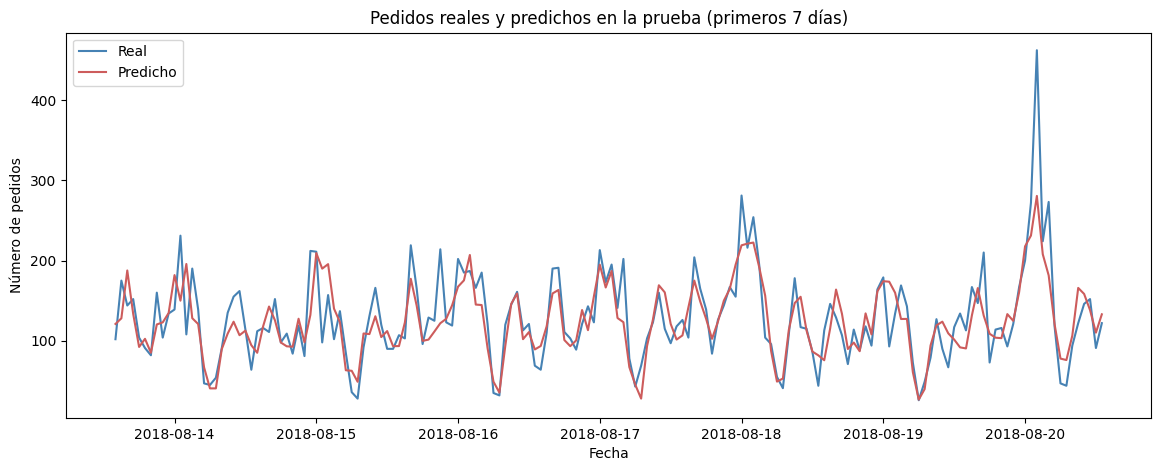

In [16]:
# comparamos los valores reales y los predichos en la prueba
# graficamos solo los primeros 7 días para que se vea el detalle del ciclo diario
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(c_test.index[:24 * 7], y_test.values[:24 * 7], color='steelblue', label='Real')
ax.plot(c_test.index[:24 * 7], predicciones[:24 * 7], color='indianred', label='Predicho')
ax.set_title('Pedidos reales y predichos en la prueba (primeros 7 días)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Número de pedidos')
ax.legend()
plt.show()

**Conclusión:** el modelo final obtiene una RECM de 34.53 en la prueba, por debajo del umbral de 48 que pide el proyecto. Supera a las tres líneas base sobre la prueba: la mediana constante (86.41), el valor de la hora anterior (58.86) y el de la semana anterior (39.55). El error de prueba es mayor que el de validación (34.53 contra 28.43) porque la prueba cae en las últimas semanas, que son las de mayor demanda y las más alejadas de lo que el modelo vio al entrenar. Aun así la regresión lineal queda por delante del bosque aleatorio (39.29) y de LightGBM (36.61) en la prueba, porque extrapola la tendencia creciente mientras que los modelos de árbol no pueden predecir valores más altos que los que vieron en el entrenamiento. En el gráfico se ve que las predicciones siguen bien el ciclo diario y se quedan un poco cortas solo en los picos más altos.

## Conclusiones generales

Remuestreé los pedidos a intervalos de una hora con la suma y pasé de 26.496 registros de 10 minutos a 4.416 horas, sin ausentes ni duplicados. En el análisis vi que la serie tiene una tendencia creciente, la media mensual sube de 57.5 pedidos en marzo a 127.7 en agosto, y una estacionalidad diaria marcada, con el pico a la medianoche y el valle a las 6 de la mañana. El efecto del día de la semana es menor. La serie original no es estacionaria, pero su diferencia de un paso sí lo es.

Para modelar creé características de calendario, 168 desfases y una media móvil calculada sobre la serie desplazada, para no filtrar la hora que quiero predecir. Separé los datos en orden cronológico sin barajar, con el último 10 % como prueba y un 10 % del resto como validación. Probé cuatro modelos distintos con varios hiperparámetros y tres tamaños de desfase, y comparé todo contra tres líneas base.

El número de desfases resultó más importante que la elección del modelo: con 24 desfases ningún modelo bajaba de 30 de RECM en validación, y con 168 la regresión lineal y los modelos de conjunto sí lo lograron. La regresión lineal con 168 desfases fue la mejor en validación (28.43) y también la más simple y rápida. En la prueba obtuvo una RECM de 34.53, por debajo del umbral de 48, y superó a las líneas base y a los modelos de árbol. Decidí quedarme con ella porque, además de ser la más precisa aquí, extrapola la tendencia creciente, algo que el bosque aleatorio y LightGBM no pueden hacer porque no predicen por encima de lo que vieron al entrenar.

# Lista de revisión

- [x] Jupyter Notebook está abierto.
- [x] El código no tiene errores
- [x] Las celdas con el código han sido colocadas en el orden de ejecución.
- [x] Los datos han sido descargados y preparados.
- [x] Se ha realizado el paso 2: los datos han sido analizados
- [x] Se entrenó el modelo y se seleccionaron los hiperparámetros
- [x] Se han evaluado los modelos. Se expuso una conclusión
- [x] La *RECM* para el conjunto de prueba no es más de 48